---
title: "Rotations, Angular Momentum Algebra and Spherical Harmonics"
short_title: "Q-M4 Rotations & Spherical Harmonics"
numbering:
  heading_2: true
  equation: true
---

# Rotations, Angular Momentum Algebra and Spherical Harmonics

:::{tip} Where this sits in the plan
Math for the **hydrogen atom**, **angular momentum and spin** and **identical particles** (quantum topics 5–7). E&M E-M2 introduced Legendre polynomials and spherical harmonics as solutions of Laplace's equation; here they reappear as eigenfunctions of angular momentum, and the algebra of rotations does most of the work.

| Item | Stewart | Boas | Zill | Arfken |
|---|---|---|---|---|
| Matrices and determinants | – | 3 | 8 | 2 |
| Groups and rotations | – | 3 | – | 16, 17 |
| Legendre polynomials and spherical harmonics | – | 12 | 5, 14 | 15, 16 |

Chapter numbers are approximate, as in the workbook.
:::

Exercises have separate hint and answer dropdowns.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import sympy as sp
from IPython.display import Math, display
from scipy.integrate import solve_ivp, quad
from scipy.optimize import brentq
from scipy import special

plt.rcParams.update({"figure.dpi": 110, "figure.figsize": (7, 4.6),
                     "axes.grid": True, "grid.alpha": 0.3})
hbar = 1.054572e-34    # J s
m_e = 9.10938e-31      # kg
eV = 1.602177e-19      # J
a0 = 5.29177e-11       # m (Bohr radius)
np.seterr(over="ignore", divide="ignore", invalid="ignore")   # plots hit inf at the edges; harmless here

{'divide': 'warn', 'over': 'warn', 'under': 'ignore', 'invalid': 'warn'}

## Rotations Do Not Commute

A rotation by angle $\theta$ about the $z$ axis is the matrix

$$
\mathsf R_z(\theta) = \begin{pmatrix}\cos\theta & -\sin\theta & 0\\ \sin\theta & \cos\theta & 0\\ 0 & 0 & 1\end{pmatrix},
$$ (eq-rz)

and similarly for $x$ and $y$. Rotations form a **group** (called SO(3)): composing two gives another, each has an inverse, and the identity is a rotation by zero. Unlike translations, they do not commute. Rotate a book 90° about $x$ then 90° about $y$, and compare with the other order: it ends up facing a different way.

**Infinitesimal rotations.** For a small angle $\epsilon$, $\mathsf R_z(\epsilon)\approx\mathsf 1 - i\epsilon\,\mathsf J_z$ with

$$
\mathsf J_z = \begin{pmatrix}0 & -i & 0\\ i & 0 & 0\\ 0 & 0 & 0\end{pmatrix}
$$

(the factor $i$ makes $\mathsf J_z$ Hermitian). The $\mathsf J$'s are the **generators** of rotations, and a finite rotation is the exponential $\mathsf R_z(\theta) = e^{-i\theta\mathsf J_z}$. The failure of rotations to commute shows up as a commutator of generators:

$$
[\mathsf J_x, \mathsf J_y] = i\mathsf J_z\quad\text{and cyclic permutations.}
$$ (eq-so3-algebra)

In quantum mechanics, the generator of rotations *is* the angular momentum divided by $\hbar$. So {eq}`eq-so3-algebra` becomes $[\hat L_x, \hat L_y] = i\hbar\hat L_z$, and that one relation determines almost everything about angular momentum.

In [2]:
th = sp.symbols("theta", real=True)
Jx = sp.Matrix([[0, 0, 0], [0, 0, -sp.I], [0, sp.I, 0]])
Jy = sp.Matrix([[0, 0, sp.I], [0, 0, 0], [-sp.I, 0, 0]])
Jz = sp.Matrix([[0, -sp.I, 0], [sp.I, 0, 0], [0, 0, 0]])
display(Math(r"[\mathsf J_x, \mathsf J_y] - i\mathsf J_z = " + sp.latex(Jx * Jy - Jy * Jx - sp.I * Jz)))
display(Math(r"e^{-i\theta \mathsf J_z} = " + sp.latex(sp.simplify((-sp.I * th * Jz).exp()))))

<IPython.core.display.Math object>

<IPython.core.display.Math object>

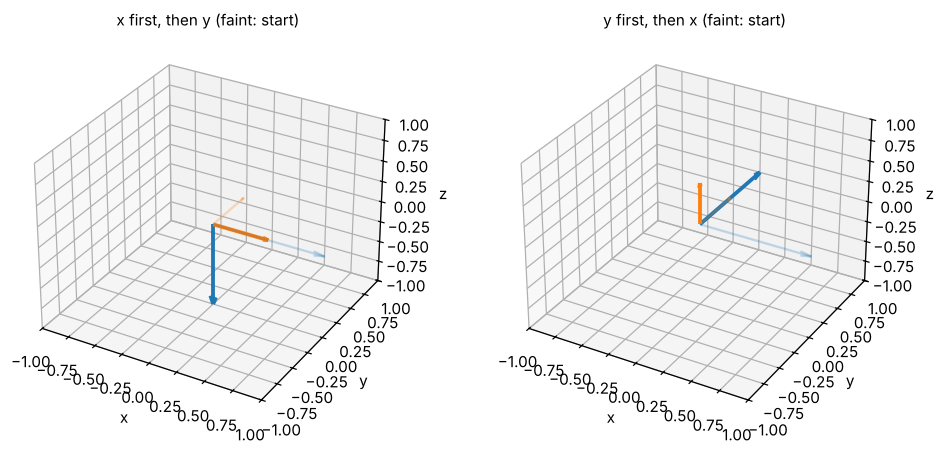

In [3]:
#| label: fig-noncommuting-rotations
#| caption: "Rotations do not commute. An arrow along x (with a short marker along y to show orientation) rotated 90° about x then 90° about y (left) ends up pointing a different way than after the same rotations in the opposite order (right)."
def R(axis, ang):
    c, s = np.cos(ang), np.sin(ang)
    return {"x": np.array([[1, 0, 0], [0, c, -s], [0, s, c]]),
            "y": np.array([[c, 0, s], [0, 1, 0], [-s, 0, c]]),
            "z": np.array([[c, -s, 0], [s, c, 0], [0, 0, 1]])}[axis]
v, w_ = np.array([1, 0, 0]), np.array([0, 0.5, 0])
fig = plt.figure(figsize=(9, 4.2))
for i, (seq, title) in enumerate([(("x", "y"), "x first, then y"), (("y", "x"), "y first, then x")]):
    ax = fig.add_subplot(1, 2, i + 1, projection="3d")
    M = R(seq[1], np.pi / 2) @ R(seq[0], np.pi / 2)
    for vec, col in [(v, "tab:blue"), (w_, "tab:orange")]:
        ax.quiver(0, 0, 0, *vec, color=col, alpha=0.25, arrow_length_ratio=0.1)
        ax.quiver(0, 0, 0, *(M @ vec), color=col, lw=2.5, arrow_length_ratio=0.1)
    ax.set_xlim(-1, 1); ax.set_ylim(-1, 1); ax.set_zlim(-1, 1)
    ax.set_xlabel("x"); ax.set_ylabel("y"); ax.set_zlabel("z"); ax.set_title(title + " (faint: start)", fontsize=10)
plt.tight_layout(); plt.show()

## Angular Momentum from Commutators Alone

Write $\hat J$ for any angular momentum (orbital, spin, or total) satisfying {eq}`eq-so3-algebra` with $\hbar$. Three facts follow from the commutators with no reference to wave functions:

1. $\hat J^2 = \hat J_x^2 + \hat J_y^2 + \hat J_z^2$ commutes with each component, so $\hat J^2$ and $\hat J_z$ have simultaneous eigenstates $|j, m\rangle$.
2. The **ladder operators** $\hat J_\pm = \hat J_x\pm i\hat J_y$ satisfy $[\hat J_z, \hat J_\pm] = \pm\hbar\hat J_\pm$, so $\hat J_\pm$ raises or lowers the $\hat J_z$ eigenvalue by $\hbar$ without changing $\hat J^2$.
3. The ladder must stop at both ends, because $\langle\hat J_z^2\rangle\le\langle\hat J^2\rangle$.

Working out where it stops gives:

$$
\hat J^2|j, m\rangle = \hbar^2j(j+1)|j, m\rangle,\qquad \hat J_z|j, m\rangle = \hbar m|j, m\rangle,\qquad m = -j, -j+1, \ldots, j ,
$$ (eq-j-eigenvalues)

with $j = 0, \tfrac12, 1, \tfrac32, \ldots$ and

$$
\hat J_\pm|j, m\rangle = \hbar\sqrt{j(j+1) - m(m\pm1)}\;|j, m\pm1\rangle .
$$ (eq-ladder-coefficients)

Half-integer $j$ is allowed by the algebra. Orbital angular momentum ($\hat{\vec L} = \hat{\vec r}\times\hat{\vec p}$) turns out to need integer $\ell$, because its eigenfunctions must be single-valued in $\phi$. Spin has no such restriction, and electrons have $s = \tfrac12$.

**Matrices for any $j$.** Equation {eq}`eq-ladder-coefficients` gives the matrices of $\hat J_\pm$ in the $(2j+1)$-dimensional basis, and then $\hat J_x = (\hat J_+ + \hat J_-)/2$, $\hat J_y = (\hat J_+ - \hat J_-)/2i$.

In [4]:
def jmats(j):
    j = sp.nsimplify(j)
    ms = [j - k for k in range(int(2 * j) + 1)]          # m = j, j-1, ..., -j
    n = len(ms)
    Jp = sp.zeros(n)
    for col, m in enumerate(ms):
        if col > 0:
            Jp[col - 1, col] = sp.sqrt(j * (j + 1) - m * (m + 1))
    Jm = Jp.T
    Jx_ = (Jp + Jm) / 2; Jy_ = (Jp - Jm) / (2 * sp.I); Jz_ = sp.diag(*ms)
    return Jx_, Jy_, Jz_
for j in [sp.Rational(1, 2), 1, sp.Rational(3, 2)]:
    X, Y, Zm = jmats(j)
    J2 = sp.simplify(X**2 + Y**2 + Zm**2)
    ok = sp.simplify(X * Y - Y * X - sp.I * Zm) == sp.zeros(X.shape[0])
    display(Math(rf"j = {sp.latex(j)}:\ \ J_x = " + sp.latex(X) + r",\quad J^2 = " + sp.latex(J2) + (r"\quad [J_x,J_y]=iJ_z\ \checkmark" if ok else "")))

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

For $j = \tfrac12$, $\hat{\vec J} = \tfrac\hbar2\vec\sigma$ with the **Pauli matrices**

$$
\sigma_x = \begin{pmatrix}0 & 1\\ 1 & 0\end{pmatrix},\quad
\sigma_y = \begin{pmatrix}0 & -i\\ i & 0\end{pmatrix},\quad
\sigma_z = \begin{pmatrix}1 & 0\\ 0 & -1\end{pmatrix} .
$$ (eq-pauli)

A rotation of a spin-½ state by $2\pi$ about any axis is $e^{-i\pi\sigma_z} = -\mathsf 1$: the state changes sign. A full turn is not the identity for spinors; it takes $4\pi$. The sign is invisible for a single particle but shows up in interference experiments with neutrons.

## Orbital Angular Momentum and Spherical Harmonics

In spherical coordinates, $\hat L_z = -i\hbar\,\partial_\phi$ and

$$
\hat L^2 = -\hbar^2\left[\frac{1}{\sin\theta}\frac{\partial}{\partial\theta}\left(\sin\theta\frac{\partial}{\partial\theta}\right) + \frac{1}{\sin^2\theta}\frac{\partial^2}{\partial\phi^2}\right] ,
$$ (eq-L2-spherical)

which is $-\hbar^2$ times the angular part of $r^2\nabla^2$. Its eigenfunctions are the **spherical harmonics** of E-M2:

$$
Y_\ell^m(\theta, \phi)\propto P_\ell^m(\cos\theta)\,e^{im\phi},\qquad \hat L^2Y_\ell^m = \hbar^2\ell(\ell+1)Y_\ell^m,\qquad \hat L_zY_\ell^m = \hbar mY_\ell^m .
$$ (eq-ylm)

The $e^{im\phi}$ factor must return to itself after $\phi\to\phi + 2\pi$, which forces integer $m$, hence integer $\ell$. They are orthonormal over the sphere, $\int Y_\ell^{m*}Y_{\ell'}^{m'}\,d\Omega = \delta_{\ell\ell'}\delta_{mm'}$, and complete: any function of direction expands in them.

(Sign conventions for $Y_\ell^m$ differ: many quantum texts include a factor $(-1)^m$ for $m > 0$, the Condon–Shortley phase. SymPy's `Ynm` includes it.)

In [5]:
thv, phv = sp.symbols("theta phi", real=True)
def L2(f):
    return -(sp.diff(sp.sin(thv) * sp.diff(f, thv), thv) / sp.sin(thv) + sp.diff(f, phv, 2) / sp.sin(thv)**2)
for l, m in [(1, 0), (1, 1), (2, 1), (3, -2)]:
    Y = sp.Ynm(l, m, thv, phv).expand(func=True)
    ratio = sp.simplify(L2(Y) / Y)
    Lz = sp.simplify(-sp.I * sp.diff(Y, phv) / Y)
    display(Math(rf"Y_{l}^{{{m}}} = " + sp.latex(sp.simplify(Y)) + r",\quad \frac{\hat L^2Y}{\hbar^2Y} = " + sp.latex(ratio) + r",\quad \frac{\hat L_zY}{\hbar Y} = " + sp.latex(Lz)))

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

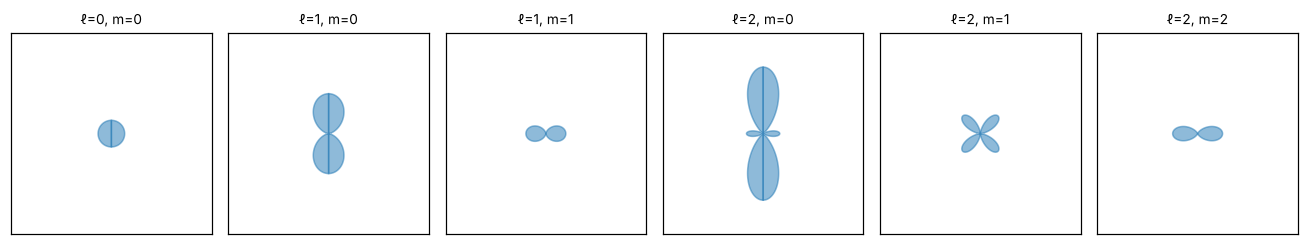

In [6]:
#| label: fig-ylm-shapes
#| caption: "Polar plots of |Y_ℓ^m(θ, φ)|² in the x–z plane (z up) for ℓ = 0, 1, 2 and m ≥ 0. The distance from the origin is the probability density in that direction. These are the angular shapes of s, p and d orbitals; |Y|² does not depend on φ, so each shape is symmetric about the z axis."
from scipy.special import sph_harm_y
tt = np.linspace(0, np.pi, 300)
fig, axes = plt.subplots(1, 6, figsize=(12, 2.6))
for ax, (l, m) in zip(axes, [(0, 0), (1, 0), (1, 1), (2, 0), (2, 1), (2, 2)]):
    rr = np.abs(sph_harm_y(l, m, tt, 0.0))**2
    for sgn in (1, -1):
        ax.fill(sgn * rr * np.sin(tt), rr * np.cos(tt), color="tab:blue", alpha=0.5)
    ax.set_aspect("equal"); ax.set_xlim(-0.6, 0.6); ax.set_ylim(-0.6, 0.6); ax.set_title(f"ℓ={l}, m={m}", fontsize=9)
    ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout(); plt.show()

## Adding Angular Momenta (a Preview)

Two angular momenta $\hat{\vec J}_1$ and $\hat{\vec J}_2$ acting on different parts of a system add to $\hat{\vec J} = \hat{\vec J}_1 + \hat{\vec J}_2$, which satisfies the same algebra. Its quantum number $j$ runs from $|j_1 - j_2|$ to $j_1 + j_2$ in integer steps. Counting checks it: $(2j_1 + 1)(2j_2 + 1) = \sum_j(2j + 1)$ over that range. Two spin-½ particles give $j = 0$ (one state, the singlet) and $j = 1$ (three states, the triplet). Quantum topic 6 builds the states; the coefficients that express them in the product basis are **Clebsch–Gordan coefficients**, and at Level 3 Sakurai derives them from rotation-group theory.

## Exercises

### Exercises

1. Verify that the Pauli matrices satisfy $\sigma_x\sigma_y = i\sigma_z$ and $\sigma_i^2 = \mathsf 1$, and deduce $[\sigma_x, \sigma_y] = 2i\sigma_z$.
2. Compute $e^{-i\theta\sigma_y/2}$ in closed form, using $\sigma_y^2 = 1$ to sum the series.
3. Use {eq}`eq-ladder-coefficients` to find $\hat J_+|1, -1\rangle$ and $\hat J_+|1, 1\rangle$.
4. Show that $\hat J^2 = \hat J_-\hat J_+ + \hat J_z^2 + \hbar\hat J_z$.
5. How many states are there for $j_1 = 1$ and $j_2 = \tfrac32$ combined? List the allowed $j$ and check the count.

:::{dropdown} Hints
1. Multiply the matrices.
2. Split the exponential series into even and odd powers.
3. $j = 1$: $\sqrt{2 - m(m+1)}$.
4. Expand $\hat J_-\hat J_+ = (\hat J_x - i\hat J_y)(\hat J_x + i\hat J_y)$ and use the commutator.
5. $j$ runs from $\tfrac12$ to $\tfrac52$.
:::

:::{dropdown} Answers
1. $\sigma_x\sigma_y = i\sigma_z$, $\sigma_y\sigma_x = -i\sigma_z$, difference $2i\sigma_z$.
2. $\cos(\theta/2)\,\mathsf 1 - i\sin(\theta/2)\,\sigma_y = \begin{pmatrix}\cos\frac\theta2 & -\sin\frac\theta2\\ \sin\frac\theta2 & \cos\frac\theta2\end{pmatrix}$. At $\theta = 2\pi$ it is $-\mathsf 1$.
3. $\hat J_+|1, -1\rangle = \sqrt2\hbar|1, 0\rangle$; $\hat J_+|1, 1\rangle = 0$.
4. $\hat J_-\hat J_+ = \hat J_x^2 + \hat J_y^2 + i[\hat J_x, \hat J_y] = \hat J^2 - \hat J_z^2 - \hbar\hat J_z$.
5. $3\times4 = 12$ states; $j = \tfrac12, \tfrac32, \tfrac52$ give $2 + 4 + 6 = 12$.
:::

## Summary

- Rotations form a non-commuting group; their generators obey $[J_x, J_y] = iJ_z$, and finite rotations are exponentials of generators.
- From the commutators alone: $\hat J^2$ eigenvalue $\hbar^2j(j+1)$, $\hat J_z$ eigenvalue $\hbar m$ with $m = -j..j$, ladder operators with known coefficients, and matrices for any $j$.
- Spin ½: $\hat{\vec J} = \tfrac\hbar2\vec\sigma$; a $2\pi$ rotation gives $-1$.
- Orbital: $\hat L^2$ is the angular Laplacian; eigenfunctions $Y_\ell^m$ with integer $\ell$.
- Adding angular momenta: $j$ from $|j_1 - j_2|$ to $j_1 + j_2$.

## Appendix: MyST patterns

Same conventions as the rest of the book: `prf:` directives for definitions, theorems and examples; `:::{dropdown}` for solutions, hints and answers; `$$ ... $$ (label)` with `` {eq}`label` `` for equations; and code cells tagged `hide-input` that start with `#| label:` and `#| caption:` lines.